# Türkiye Elektrik İletim Altyapısı — Ağ Analizi

**Said Özen · 2516016014 · Sosyal Ağ Analizi (MCBÜ Büyük Veri Analistliği)**

**Araştırma sorusu:** İletim ağında hangi trafo merkezleri tek hata noktası? Basit bir zincirleme arıza nasıl yayılır?

**Kaynak:** OpenStreetMap Overpass API (`power=line`, `power=substation`), © OpenStreetMap katkıcıları, ODbL.
**Düğüm:** trafo merkezi · **Kenar:** iletim hattı · yönsüz, ağırlıksız.

Bu defter depodaki betikleri sırayla çağırır ve sonuçları yorumlar. Uzun süren adımlar (kaskad deneyleri ve 200 rastgele ağlı null model, toplam ~20 dk) `TAM_CALISTIR = False` iken `results/` klasöründeki kayıtlı sonuçlardan okunur; `True` yapılırsa yeniden hesaplanır. Tüm rastgele işlemler tohum 42 ile sabittir.

**Not:** Leiden, Python'un küme sırasından etkilenir. Sonuçların `results/` ile birebir aynı çıkması için Jupyter'i `PYTHONHASHSEED=0 jupyter notebook` komutuyla başlatın.

In [1]:
import json, sys, subprocess
from pathlib import Path
import networkx as nx
import pandas as pd
from IPython.display import Image, display  # Jupyter dışında da çalışır

KOK = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(KOK))
from src import analiz, kaskad

TAM_CALISTIR = False   # True: kaskad + null model yeniden hesaplanır (~20 dk)
TOHUM = 42
pd.set_option("display.precision", 3)
print("networkx", nx.__version__, "| pandas", pd.__version__)

networkx 3.7 | pandas 3.0.5


## 1. Veri toplama
`src/veri_topla.py` trafo merkezlerini ve hatları indirir. Tüm Türkiye için tek hat sorgusu Overpass sunucusunda zaman aşımına uğradığından hatlar `src/hatlari_parcali_indir.py` ile 12 karoda indirildi. İndirme ~30 dk sürebildiği için aşağıdaki komutlar yorum satırıdır; ham veri `data/raw/` klasöründedir.

In [2]:
# !python src/veri_topla.py              # trafo merkezleri (+ tek sorguda hatlar)
# !python src/hatlari_parcali_indir.py   # hatlar, 12 karo
meta = json.loads((KOK / "data/raw/meta.json").read_text(encoding="utf-8"))
ham_trafo = json.loads((KOK / "data/raw/substations.json").read_text(encoding="utf-8"))["elements"]
ham_hat = json.loads((KOK / "data/raw/lines.json").read_text(encoding="utf-8"))["elements"]
print(meta)
print("OSM trafo merkezi nesnesi:", len(ham_trafo))
print("OSM iletim hattı (way):", sum(e["type"] == "way" for e in ham_hat))

{'indirme_zamani_utc': '2026-10-28T19:03:50+00:00', 'yontem': 'trafolar tek sorgu; hatlar 3x4 karo, her karoda (area.tr)', 'lisans': '© OpenStreetMap katkıcıları, ODbL 1.0'}
OSM trafo merkezi nesnesi: 4384
OSM iletim hattı (way): 4698


## 2. Ağ kurma
`src/ag_kur.py`: hat uçları trafo alanına (50 m pay) ya da 300 m yakınına düşüyorsa o merkeze eşlenir; parçalı hatlar ve T-branşmanlar ortak direklerde birleştirilir; ≥ 66 kV ya da gerilimi etiketsiz hatlar alınır. Gerekçeler `docs/veri_sozlugu.md` dosyasında.

In [3]:
subprocess.run([sys.executable, str(KOK / "src/ag_kur.py")], check=True, capture_output=True)
rapor = json.loads((KOK / "data/processed/build_report.json").read_text(encoding="utf-8"))
pd.Series(rapor["ana_ag"], name="sayı").to_frame()

,sayı
osm_trafo_merkezi,4243
osm_hat_yolu,4698
hat_gerilim_bilinmiyor,1221
hat_dagitim_seviyesi_elenen,28
hat_secilen,4670
uc_nokta,7168
uc_nokta_yapisan,3986
sarkan_uc_nokta,1719
kume_3ten_fazla_trafo,99
kume_trafoya_degmeyen,438


In [4]:
G = nx.read_graphml(KOK / "data/processed/grid.graphml")
H = analiz.en_buyuk_bilesen(G)
print(f"Ağ: {G.number_of_nodes()} düğüm, {G.number_of_edges()} kenar")
print(f"En büyük bileşen: {H.number_of_nodes()} düğüm, {H.number_of_edges()} kenar")
pd.read_csv(KOK / "data/processed/edges.csv").head()

Ağ: 1193 düğüm, 1543 kenar
En büyük bileşen: 1072 düğüm, 1449 kenar


,kaynak,hedef,uzunluk_km,gerilim_kv,hat_sayisi,bransman
0,n12318836109,w1346435921,6.01,154,1,0
1,n2778757730,w259052265,9.44,154,1,0
2,n2778758017,w1137174185,18.78,154,5,1
3,n2778758017,w127973572,22.01,154,1,0
4,n2778758017,w176358448,52.51,154,5,1


## 3. Temel ölçüler

In [5]:
temel = pd.DataFrame({"tüm ağ": analiz.temel_olculer(G), "en büyük bileşen": analiz.temel_olculer(H)})
temel

,tüm ağ,en büyük bileşen
dugum_sayisi,1193,1072
kenar_sayisi,1543,1449
yogunluk,0.002,0.003
ortalama_derece,2.587,2.703
maksimum_derece,15,15
bilesen_sayisi,39,1
en_buyuk_bilesen_dugum,1072,1072
en_buyuk_bilesen_oran,0.899,1.0
ortalama_kumelenme,0.204,0.204
gecislilik_transitivity,0.161,0.157


**Yorum.**
- *Yoğunluk 0,0022, ortalama derece 2,6:* her merkez yalnızca yakınındaki 2–3 merkeze bağlı; hat yapmak pahalı olduğu için şebeke seyrek.
- *39 bileşen:* ana parça merkezlerin %90'ı; 38 küçük parça büyük olasılıkla OSM'de çizilmemiş bağlantı hatlarından kaynaklanıyor.
- *Ortalama en kısa yol 12,7, çap 35:* iki merkez arasında ortalama 12,7 hat var; coğrafya yüzünden "küçük dünya" değil.
- *Kümelenme 0,20:* bir merkezin iki komşusunun birbirine de bağlı olma olasılığı %20; bu üçgenler enerjiye alternatif yol açan halkalar.
- *Derece benzeşimi ≈ 0:* büyük merkezler özellikle büyüklerle bağlanmıyor.

{
 "alpha": 3.797975315474623,
 "xmin": 4.0,
 "sigma": 0.17385772670536004,
 "karsilastirma_power_law_vs": {
  "exponential": {
   "R": -0.3539957532235139,
   "p": 0.7233420658776353
  },
  "lognormal": {
   "R": -1.773073393283578,
   "p": 0.07621654614591357
  }
 },
 "aciklama": "R>0 power-law'un digerinden daha iyi, R<0 digeri daha iyi; p<0.05 ise fark anlamli."
}


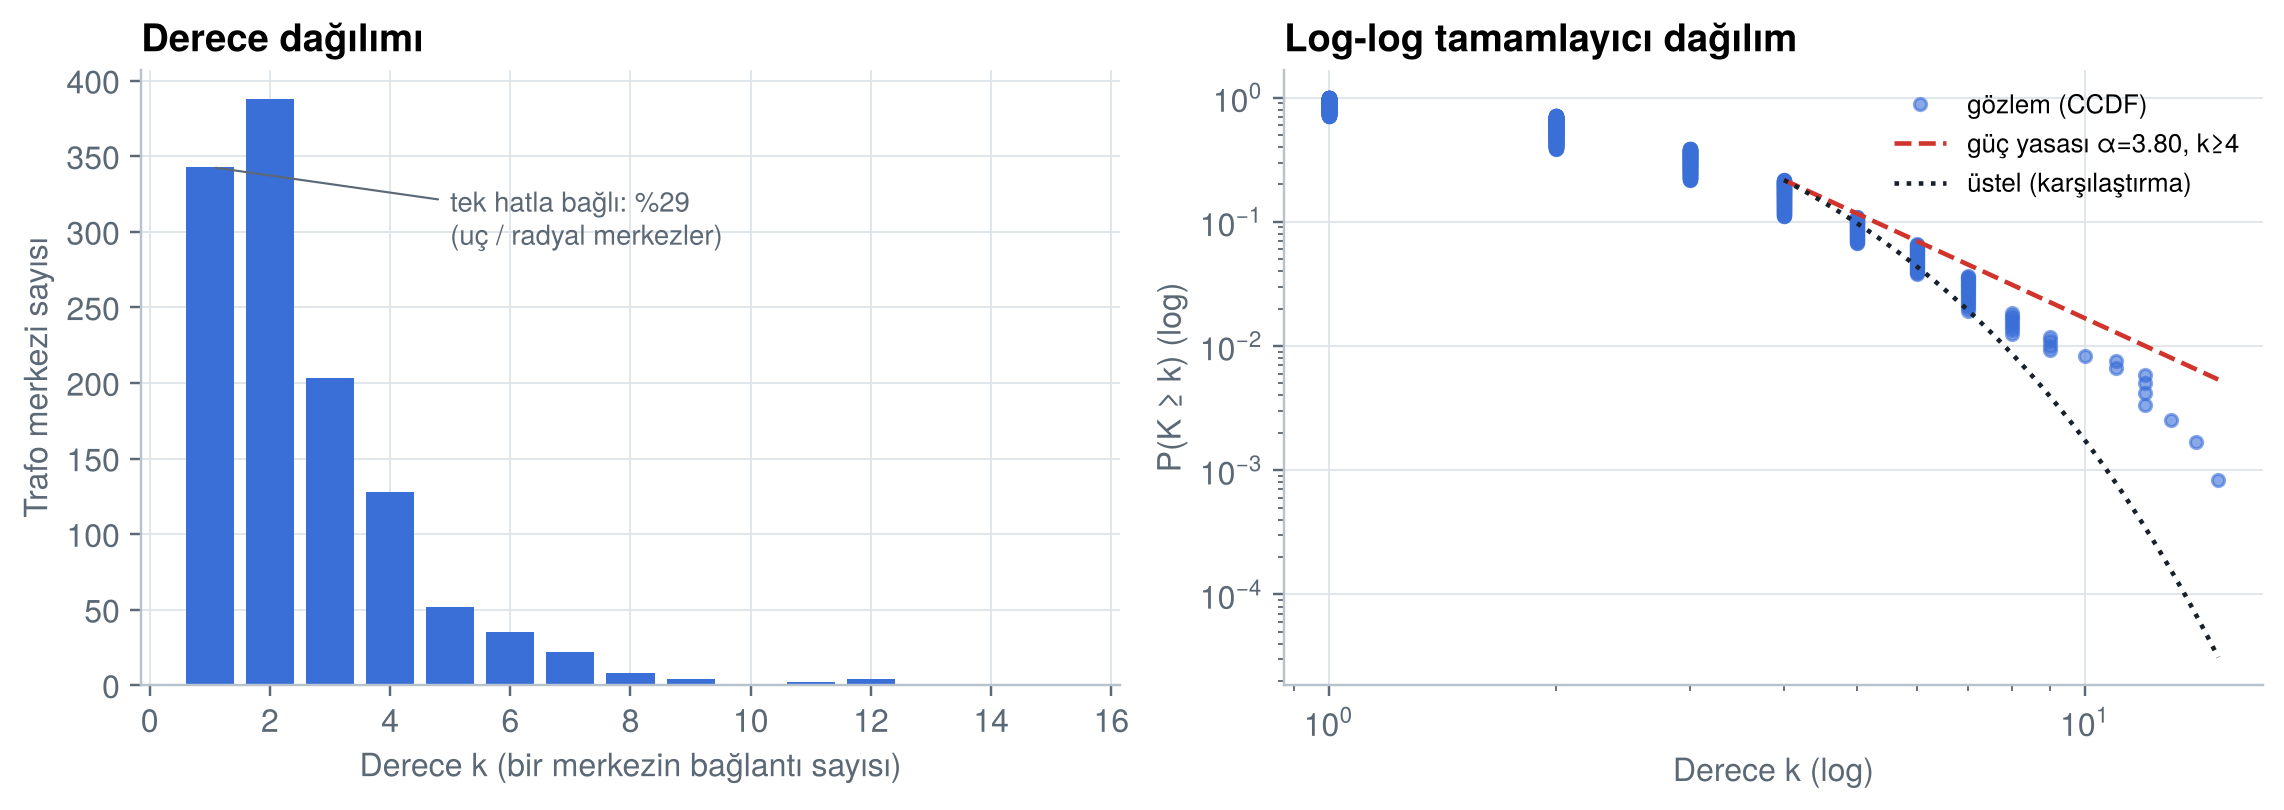

In [6]:
dd = analiz.derece_dagilimi(G, pl_yolu=(str(KOK / ".vendor"),))
print(json.dumps(dd["powerlaw"], ensure_ascii=False, indent=1))
Image(filename=str(KOK / "figures/derece_dagilimi.png"), width=850)

**Yorum.** Kuvvet yasası k ≥ 4 için α ≈ 3,8 verse de üstel (R < 0, p = 0,72) ve log-normal (R < 0, p = 0,08) dağılımdan daha iyi uymuyor. Derece dağılımı üstel benzeri: şebeke birkaç dev merkeze değil, uzun hat zincirlerine dayanıyor (Avrupa ve ABD şebekeleriyle uyumlu).

## 4. Merkeziyet

In [7]:
mc = analiz.merkeziyetler(G)
ilk = pd.DataFrame({olcu: [f"{r['ad']} ({r['il']})" for r in kayit] for olcu, kayit in mc["ilk_n"].items()},
                   index=range(1, 11))
ilk

,derece,betweenness,closeness,eigenvector,pagerank
1,Aliağa-2 TM (İzmir),Osmanca TM (Düzce),Osmanca TM (Düzce),Adapazarı-2 TM (Sakarya),Aliağa-2 TM (İzmir)
2,Adapazarı-2 TM (Sakarya),Kurşunlu TM (Çankırı),Kurşunlu TM (Çankırı),Osmanca TM (Düzce),Adapazarı-2 TM (Sakarya)
3,Seydişehir TM (Konya),Kayabaşı 380kV TM (Amasya),Kayabaşı 380kV TM (Amasya),Tepeören TM (Yalova),Seydişehir TM (Konya)
4,Diyarbakır-3 TM (Diyarbakır),Adapazarı-2 TM (Sakarya),Adapazarı-2 TM (Sakarya),Uludağ GİS Transformatör Merkezi (Bursa),Osmanca TM (Düzce)
5,Afşin-Elbistan A TES TM (Kahramanmaraş),Uludağ GİS Transformatör Merkezi (Bursa),DEÇEKO TM (Sivas),Kocaeli TM (Kocaeli),Tepeören TM (Yalova)
6,Balıkesir-2 TM (Balıkesir),Soma-B TES TM (Balıkesir),Resadiye TM (Tokat),TEİAŞ Kocaeli 380 Trafo Merkezi (Kocaeli),Balıkesir-2 TM (Balıkesir)
7,Osmanca TM (Düzce),Aktaş 4701 TM (İstanbul),Uludağ GİS Transformatör Merkezi (Bursa),Afşin-Elbistan A TES TM (Kahramanmaraş),Diyarbakır-3 TM (Diyarbakır)
8,Tepeören TM (Yalova),Erzin TM (Osmaniye),Kangal TES TM (Sivas),Adapazarı-1 DGKÇ (Sakarya),Kayabaşı 380kV TM (Amasya)
9,Kayabaşı 380kV TM (Amasya),Kangal TES TM (Sivas),Bağlum TM (Ankara),TM (Kocaeli),Afşin-Elbistan A TES TM (Kahramanmaraş)
10,Atatürk HES TM (Adıyaman),DEÇEKO TM (Sivas),Keban HES TM (Elazığ),Bursa DGKÇS TM (Bursa),Işıklar TM (İzmir)


In [8]:
mc["spearman"].round(2)

,derece,betweenness,closeness,eigenvector,pagerank
derece,1.00,0.84,0.31,0.32,0.96
betweenness,0.84,1.00,0.34,0.30,0.84
closeness,0.31,0.34,1.00,0.93,0.18
eigenvector,0.32,0.30,0.93,1.00,0.18
pagerank,0.96,0.84,0.18,0.18,1.00


**Yorum.** *Betweenness:* tüm en kısa yolların %44'ü Osmanca'dan (Düzce), %37'si Kurşunlu'dan (Çankırı), %35'i Kayabaşı'ndan (Amasya) geçiyor; üçü de Marmara'yı doğuya bağlayan 380 kV koridorunda. *Derece/PageRank:* santral ve sanayi bölgeleri (Aliağa, Seydişehir, Afşin-Elbistan). *Closeness:* şebekenin ortasındaki koridor ve İç Anadolu. *Eigenvector:* yoğun bağlı Kocaeli–Sakarya–Bursa çekirdeği. Spearman iki aile gösteriyor: {derece, PageRank, betweenness} ve {closeness, eigenvector}.

## 5. Topluluk tespiti

In [9]:
top = analiz.topluluk_tespiti(G)
top.pop("_louvain_partisyon")
pd.DataFrame({k: top[k] for k in ("louvain", "leiden")}).T

,topluluk_sayisi,modularite,hata
louvain,25.0,0.89,NaN
leiden,25.0,0.89,NaN


In [10]:
pd.DataFrame({"Louvain (10 tohum)": top["kararlilik"], "Leiden (10 tohum)": top["kararlilik_leiden"]}).T

,tekrar,nmi_ortalama,nmi_std,ari_ortalama,ari_std,modularite_ortalama,modularite_std
Louvain (10 tohum),10.0,0.901,0.025,0.782,0.066,0.889,1.140e-03
Leiden (10 tohum),10.0,0.900,0.017,0.775,0.044,0.889,7.891e-04


In [11]:
pd.DataFrame(top["buyuk_topluluk_adlari"])[["dugum_sayisi", "baslica_iller", "baslica_merkezler"]]

,dugum_sayisi,baslica_iller,baslica_merkezler
0,118,"Tekirdağ, İstanbul, Kırklareli","[Habibler TM, Malkara TM, TEİAŞ 154KV Çorlu Tr..."
1,76,"Yalova, Kocaeli, İstanbul","[Adapazarı-2 TM, Osmanca TM, Tepeören TM]"
2,64,"Antalya, Karaman, Konya","[Seydişehir TM, Varsak TM, Oymapınar HES TM]"
3,63,"Amasya, Ankara, Giresun","[Kayabaşı 380kV TM, Kurşunlu TM, Çankırı TM]"
4,60,"Kahramanmaraş, Sivas, Malatya","[Afşin-Elbistan A TES TM, Keban 154kV TM, Bağı..."


**Yorum.** Q = 0,889: hatların %94'ü aynı topluluk içindeki merkezleri bağlıyor. 10 tohumla NMI ≈ 0,92: büyük toplulukların sınırı kararlı. Verilen adlar: **Trakya**, **Konya–Antalya**, **Afşin-Elbistan–Keban**, **Doğu Marmara**, **İzmir–Manisa** (ardından Diyarbakır–Mardin, Van Gölü havzası, Çukurova).

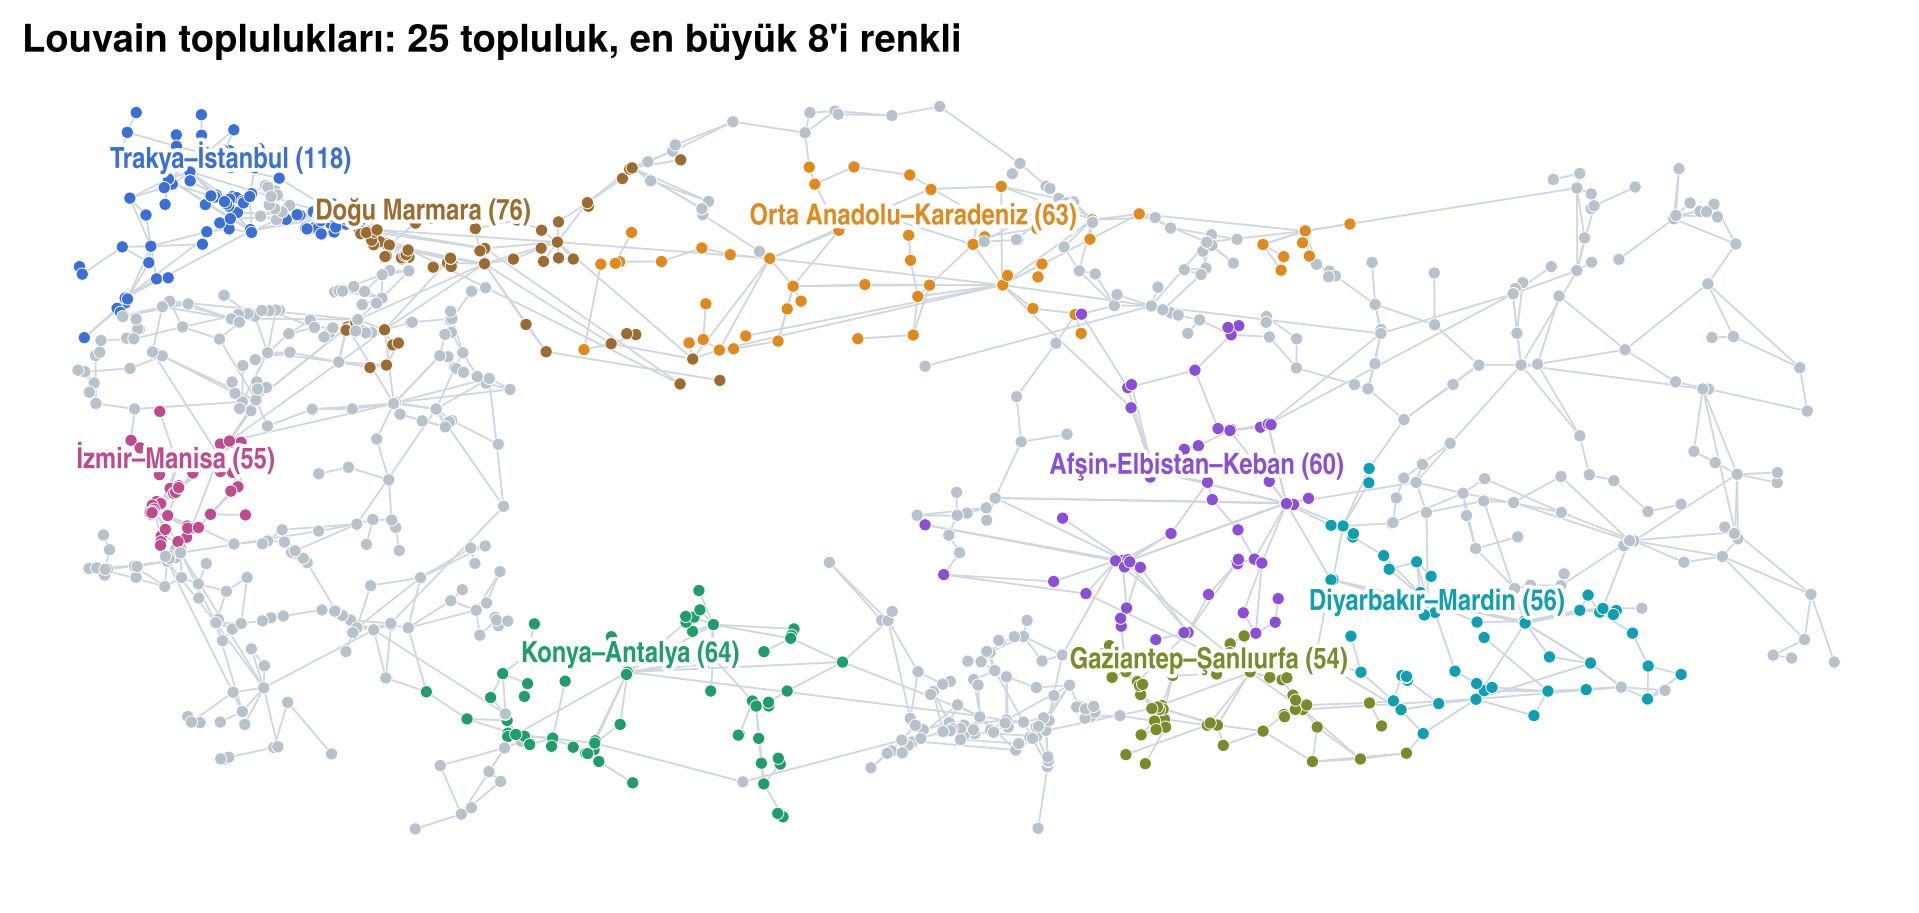

In [12]:
Image(filename=str(KOK / "figures/topluluklar.png"), width=850)

## 6. Null model (100 configuration + 100 Erdős–Rényi)

In [13]:
if TAM_CALISTIR:
    nm = analiz.null_model(G, tekrar=100); nm.pop("_dagilim")
else:
    nm = json.loads((KOK / "results/analiz.json").read_text(encoding="utf-8"))["null_model"]
pd.DataFrame(nm["karsilastirma"]["configuration"]).T[["gozlem", "null_ortalama", "null_std", "z_skoru"]]

,gozlem,null_ortalama,null_std,z_skoru
ortalama_kumelenme,0.204,0.002,0.001,141.617
ortalama_en_kisa_yol,12.690,6.907,0.063,91.256
derece_assortativity,-0.027,-0.002,0.027,-0.929
modularite,0.890,0.716,0.004,45.219


**Yorum.** Kümelenme (z = 140), ortalama yol (z = 88) ve modülerlik (z = 48) rastlantıyla açıklanamaz. Aynı derecelerle rastgele ağlar bile Q ≈ 0,72 alıyor; null model olmasaydı "0,89 yüksek" demek yanıltıcı olurdu. Derece benzeşimi rastgele ağdan farksız (z = −1).

## 7. İleri yöntem: eklem noktaları ve köprüler

In [14]:
th = kaskad.tek_hata_noktalari(G)
eklem = pd.DataFrame(th.pop("_eklem_hepsi")); th.pop("_kopru_hepsi")
print({k: (round(v, 3) if isinstance(v, float) else v) for k, v in th.items() if not k.startswith("en_")})
eklem[["ad", "il", "gerilim_kv", "derece", "kopan_dugum", "kopan_iller"]].head(15)

{'dugum': 1072, 'eklem_noktasi_sayisi': 326, 'eklem_orani': 0.304, 'kopru_sayisi': 367, 'kopru_orani': 0.253, 'eklem_10dan_fazla_koparan': 14, 'eklem_sadece_1_koparan': 162, 'kopru_10dan_fazla_koparan': 6, 'yaprak_dugum_derece1': 275, 'iki_cekirdek_dugum': 726, 'iki_cekirdek_oran': 0.677}


,ad,il,gerilim_kv,derece,kopan_dugum,kopan_iller
0,Kozan TM,Osmaniye,154,4,15,"[Adana, Kahramanmaraş, Osmaniye]"
1,Kozan Havza TM,Adana,154,4,14,"[Adana, Kahramanmaraş, Osmaniye]"
2,Balıkesir-2 TM,Balıkesir,400,12,12,"[Balıkesir, Çanakkale]"
3,Küre TM,Kastamonu,154,4,11,"[Bartın, Karabük, Zonguldak, Çankırı]"
4,Silivri TM,Tekirdağ,154,4,11,"[Tekirdağ, İstanbul]"
5,Bursa DGKÇ TM,Bursa,400,3,11,"[Bursa, Yalova]"
6,Aliağa-2 TM,İzmir,400,15,10,[İzmir]
7,Osmanca TM,Düzce,400,12,10,"[Bartın, Düzce, Zonguldak]"
8,Yatağan TES TM,Muğla,400,9,10,"[Aydın, Muğla]"
9,Orhangazi TM,Yalova,154,7,10,"[Bursa, Yalova]"


**Yorum.** 326 eklem noktası (%30) ve 367 köprü var, çünkü merkezlerin yalnızca %68'i bir halka üzerinde (2-çekirdek). Ama 162 eklem noktası sadece 1 merkez koparıyor; 10+ merkez koparan 14 tane: Kozan, Kozan Havza, Balıkesir-2, Silivri, Küre, Bursa DGKÇ… Bunlar radyal kolların başındaki merkezler.

## 8. İleri yöntem: yük yeniden dağıtımıyla kaskad (Motter–Lai)
Yük L = merkezden geçen en kısa yol sayısı; kapasite C = (1+α)·L(0). Bir merkez düşer, yükler kalan ağda yeniden hesaplanır, kapasiteyi aşanlar düşer, aşan kalmayınca durur. G = ayakta kalan en büyük parça / başlangıç.

In [15]:
L0 = nx.betweenness_centrality(H, normalized=False)
osmanca = max(L0, key=L0.get)
r = kaskad.kaskad(H, L0, osmanca, alfa=0.25)
print(H.nodes[osmanca]["ad"], "| dalga boyutları:", [len(d) for d in r["dalgalar"]],
      "| düşen:", r["dusen_toplam"], "| G =", round(r["G"], 3))

Osmanca TM | dalga boyutları: [1, 67, 31, 1, 1, 1] | düşen: 102 | G = 0.338


In [16]:
if TAM_CALISTIR:
    kd = kaskad.kaskad_deneyleri(G, eklem.to_dict("records")); kd.pop("L0"); ozet = kd["ozet"]
else:
    ozet = json.loads((KOK / "results/analiz.json").read_text(encoding="utf-8"))["kaskad"]["ozet"]
pd.DataFrame({g: {a: v["G_ortalama"] for a, v in d.items()} for g, d in ozet.items()}).T.rename_axis("başlangıç grubu / α")

,0.1,0.25,0.5,1.0
başlangıç grubu / α,,,,
en_yuksek_betweenness,0.321,0.324,0.431,0.525
en_kritik_eklem,0.738,0.836,0.850,0.888
rastgele,0.827,0.966,0.982,0.991


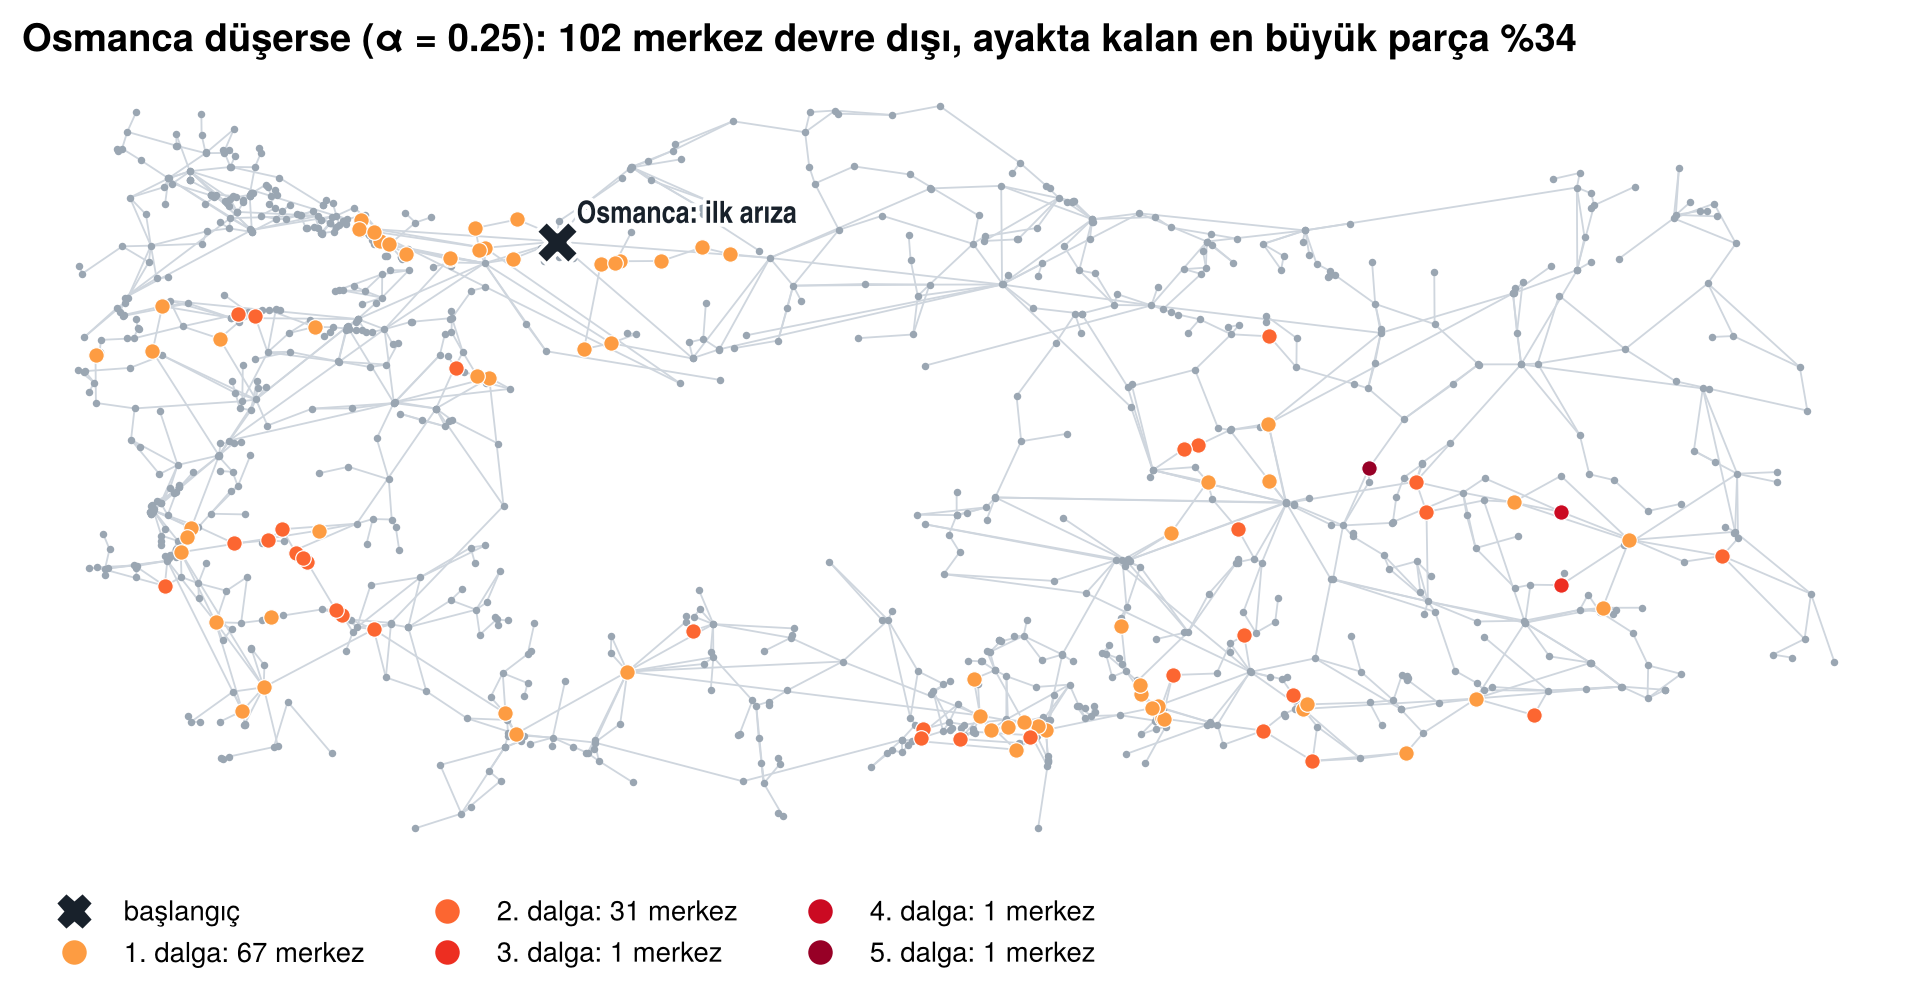

In [17]:
Image(filename=str(KOK / "figures/kaskad_dalgalar.png"), width=850)

**Yorum.** Rastgele bir merkezin kaybı (α = 0,25) şebekenin %97'sini ayakta bırakıyor; en yüklü 10 merkezden biri düşerse ayakta kalan en büyük parça ortalama %32. Osmanca düşünce batı–doğu yükü güney koridoruna kayıyor (Erzin, Varsak, Yatağan, Seydişehir…): 1. dalgada 67, 2. dalgada 31 merkez düşüyor ve şebeke bölgesel adalara bölünüyor. Eklem noktalarından başlayan kaskadlar sınırlı (G = 0,84).

## Sonuç
Bölgeyi karanlıkta bırakan merkezler (eklem noktaları) radyal kollarda; ülke geneline yayılan arızayı başlatan merkezler Osmanca–Kurşunlu–Kayabaşı 380 kV koridorunda. **Sınırlar:** OSM eksik (hatların %26'sı gerilimsiz, 38 kopuk parça) ve Motter–Lai modeli gerçek AC güç akışı değildir; ayrıntı raporda.